In [1]:
import torch
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn

In [2]:
IC_coefficients = torch.load('./results/wave_equation/ic_coeff_20_3.pt')
IC_neuman_coeffs = torch.load('./results/wave_equation/ic_neum_coeff_20_3.pt')

C:\Users\Polydoras\AppData\Local\Temp\ipykernel_25964\2491872304.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  IC_coefficients = torch.load('./results/wave_equation/ic

In [3]:

class bsplines2D(nn.Module):

    def __init__(self, n_basis, degree):
        super().__init__()
        self.degree = degree
        self.n_basis = n_basis
        self.n_knots = n_basis + degree + 1
        # Uniform clamped bsplines
        knot_vector = torch.linspace(0, 1, self.n_knots - 2 * degree)
        self.knot_vector = torch.cat((
                torch.full((degree,), knot_vector[0]),
                knot_vector,
                torch.full((degree,), knot_vector[-1])
            ))
        
        # Same knot vector in every direction
        self.knot_x = self.knot_vector.clone()
        self.knot_t = self.knot_vector.clone()

        # 2D interior domain trainable coefficients
        self.coeffs_trainable = torch.rand(n_basis-2, n_basis-2)

        # Define the coeff based on the Dirichlet boundary conditions.
        # IC at t=0
        self.coeffs_row_0=IC_coefficients
        self.coeffs_row_1=IC_neuman_coeffs
        
        # BC 
        self.coeffs_rl = torch.tensor([0.0])
        self.coeffs_trainable.requires_grad_()
        # 2D input
        # self.x = x
        
        
        # Bsplines for the two dimensions
        ################Changes#################
        # self.D = torch.rand(1)
        # self.D.requires_grad_()
        self.raw_c = nn.Parameter(torch.tensor([0.1], dtype=torch.float32))  # initial guess
        self.softplus = nn.Softplus()
        ################Changes#################

        
    def bspline_basis(self,i, p, x, knots):
        if p == 0:

            #######Change#############
            #In degree 2 when I put = it gets bad
            # return ((x >= knots[i]) & (x <= knots[i+1])).float()
            return ((x >= knots[i]) & (x < knots[i+1])).float()
            #######Change#############
        
        else:
            denom1 = knots[i+p] - knots[i]
            denom2 = knots[i+p+1] - knots[i+1]

            term1 = 0.0
            if denom1 > 0:
                term1 = (x - knots[i]) / denom1 * self.bspline_basis(i, p-1, x, knots)

            term2 = 0.0
            if denom2 > 0:
                term2 = (knots[i+p+1] - x) / denom2 * self.bspline_basis(i+1, p-1, x, knots)

            return term1 + term2

    def forward(self,x):

        self.B_x = torch.stack([self.bspline_basis(i, self.degree, x[:,0], self.knot_x ) for i in range(self.n_basis)])
        self.B_t = torch.stack([self.bspline_basis(j, self.degree, x[:,1], self.knot_t) for j in range(self.n_basis)])


        y = torch.zeros(x.shape[0])
        # Adding the internal domain bsplines
        for i in range(2,self.n_basis):
            for j in range(1,self.n_basis-1):
                y += self.coeffs_trainable[i-2, j-1] * self.B_t[i]*self.B_x[j]

        # Adding the Dirichlet IC  
        for i in range(self.n_basis):
            y += self.coeffs_row_0[i]*self.B_t[0]*self.B_x[i]

        # Adding the Neumann IC in the second row  
        for i in range(self.n_basis):
            y += self.coeffs_row_1[i]*self.B_t[1]*self.B_x[i]

        #Adding BC to the left side
        for i in range(2,self.n_basis):

            y+=self.coeffs_rl*self.B_t[i]*self.B_x[0]

        #Adding BC to the left side
        for i in range(2,self.n_basis):

            y+=self.coeffs_rl*self.B_t[i]*self.B_x[self.n_basis-1]


        return y
    
    def c(self):
        return self.softplus(self.raw_c)
    
   


Class for noisy data where we can not impose exact conditions

In [2]:

class bsplines2D(nn.Module):

    def __init__(self, n_basis, degree, device):
        super().__init__()
        self.degree = degree
        self.n_basis = n_basis
        self.n_knots = n_basis + degree + 1
        # Uniform clamped bsplines
        knot_vector = torch.linspace(0, 1, self.n_knots - 2 * degree)
        self.knot_vector = torch.cat((
                torch.full((degree,), knot_vector[0]),
                knot_vector,
                torch.full((degree,), knot_vector[-1])
            ))
        
        # Same knot vector in every direction
        self.knot_x = self.knot_vector.clone()
        self.knot_t = self.knot_vector.clone()

        # 2D interior domain trainable coefficients (needs first to require grad and then to send to device.)
        self.coeffs_trainable = torch.zeros(n_basis, n_basis,device=device, requires_grad=True)

      
        self.raw_c = nn.Parameter(torch.tensor([0], dtype=torch.float32))  # initial guess
        self.softplus = nn.Softplus()
        ################Changes#################

        
    def bspline_basis(self,i, p, x, knots):
        if p == 0:

            #######Change#############
            #In degree 2 when I put = it gets bad
            return ((x >= knots[i]) & (x <= knots[i+1])).float()
            # return ((x >= knots[i]) & (x < knots[i+1])).float()
            #######Change#############
        
        else:
            denom1 = knots[i+p] - knots[i]
            denom2 = knots[i+p+1] - knots[i+1]

            term1 = 0.0
            if denom1 > 0:
                term1 = (x - knots[i]) / denom1 * self.bspline_basis(i, p-1, x, knots)

            term2 = 0.0
            if denom2 > 0:
                term2 = (knots[i+p+1] - x) / denom2 * self.bspline_basis(i+1, p-1, x, knots)

            return term1 + term2

    def forward(self,x, device):

        self.B_x = torch.stack([self.bspline_basis(i, self.degree, x[:,0], self.knot_x ) for i in range(self.n_basis)])
        self.B_t = torch.stack([self.bspline_basis(j, self.degree, x[:,1], self.knot_t) for j in range(self.n_basis)])



        y = torch.zeros(x.shape[0], device=device)
        # Adding the internal domain bsplines
        for i in range(self.n_basis):
            for j in range(self.n_basis):
                y += self.coeffs_trainable[i, j] * self.B_t[i]*self.B_x[j]



        return y
    
    def c(self):
        return self.softplus(self.raw_c)
    
    # send every attribute to device
    def to(self, device):
        for attr, value in self.__dict__.items():
            if isinstance(value, torch.Tensor):
                setattr(self, attr, value.to(device))
   


In [3]:
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [4]:
torch.manual_seed(42)

model = bsplines2D(20,3, device)
model.coeffs_trainable.shape

torch.Size([20, 20])

In [5]:
model.to(device)

In [5]:
# 🔍 Evaluate on a grid
x = y = np.linspace(0, 1, 100)
Xg, Tg = np.meshgrid(x, y)
XY = np.vstack([Xg.ravel(), Tg.ravel()]).T
XY_torch = torch.tensor(XY, dtype=torch.float32)

# Prediction
with torch.no_grad():
    u_pred = model.forward(XY_torch).numpy().reshape(Xg.shape)

# ✅ Exact solution
u_exact = np.sin(np.pi * Xg) * np.cos(np.pi*Tg)


fig, axs = plt.subplots(1, 3, figsize=(15, 4))
# PINN solution
im0 = axs[0].imshow(u_pred, extent=[0,1,0,1], origin='lower', cmap='viridis')
axs[0].set_title("Physics_Informed_bsplines Solution")
fig.colorbar(im0, ax=axs[0])

# Exact solution
im1 = axs[1].imshow(u_exact, extent=[0,1,0,1], origin='lower', cmap='viridis')
axs[1].set_title("Exact Solution")
fig.colorbar(im1, ax=axs[1])

# Absolute error
error = np.abs(u_pred - u_exact)
im2 = axs[2].imshow(error, extent=[0,1,0,1], origin='lower', cmap='hot')
axs[2].set_title("Absolute Error")
fig.colorbar(im2, ax=axs[2])

for ax in axs:
    ax.set_xlabel("x")
    ax.set_ylabel("y")

plt.tight_layout()
plt.show()

TypeError: forward() missing 1 required positional argument: 'device'

In [6]:
nn.Softplus(model.raw_c)

Softplus(
  beta=Parameter containing:
  tensor([0.], requires_grad=True), threshold=20.0
)

In [6]:
colloc_points = 5000

# Reproducable input points
torch.manual_seed(42)

X = torch.rand(colloc_points,2)
#########Change###########
u_exact = torch.sin(torch.pi * X[:,0]) * torch.cos(torch.pi*X[:,1])
u_exact = u_exact.to(device)
noise = torch.normal(mean=0.0, std=0.05, size=u_exact.shape)
noise = noise.to(device)
u_noisy = u_exact + noise
#########Change###########
X = X.to(device)
X.requires_grad_(True)

tensor([[0.8823, 0.9150],
        [0.3829, 0.9593],
        [0.3904, 0.6009],
        ...,
        [0.9278, 0.5794],
        [0.8308, 0.2181],
        [0.9120, 0.4111]], device='cuda:0', requires_grad=True)

In [7]:
model.forward(X, device)

tensor([-0.3433, -0.9223, -0.2911,  ..., -0.0550,  0.3901,  0.0739],
       device='cuda:0', grad_fn=<AddBackward0>)

In [10]:
epochs = 2000
learning_rate=1e-4

###########Changes#################
optimizer = torch.optim.Adam([model.coeffs_trainable, model.raw_c], lr=learning_rate)
###########Changes#################

loss_vec = []
for epoch in range(epochs):

    optimizer.zero_grad()

    u = model.forward(X, device)
    grads = torch.autograd.grad(u, X, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = grads[:, 0]
    u_t = grads[:, 1]
    u_xx = torch.autograd.grad(u_x, X, torch.ones_like(u_x), create_graph=True)[0][:, 0]
    u_tt = torch.autograd.grad(u_t, X, torch.ones_like(u_x), create_graph=True)[0][:, 1]

    c = model.c().to(device)

    # Residual loss
    res = u_tt -c*u_xx
    
    loss_pde = torch.mean(res**2)
    loss_data = torch.mean((u - u_noisy)**2) 
    loss = loss_pde + 100*loss_data

    loss.backward()
    optimizer.step()
    
    loss_vec.append(loss.item())
    # Print loss and parameters every 100 iterations
    if (epoch + 1) % 5 == 0:
        c_est = c.item()
        print(f"Epoch {epoch:5d} | Loss: {loss.item():} | D: {c_est:}")

Epoch     4 | Loss: 0.25687992572784424 | D: 0.9769113659858704
Epoch     9 | Loss: 0.2529160678386688 | D: 0.9769143462181091
Epoch    14 | Loss: 0.25077369809150696 | D: 0.9768600463867188
Epoch    19 | Loss: 0.24961237609386444 | D: 0.9768819808959961
Epoch    24 | Loss: 0.2491496354341507 | D: 0.9768561124801636
Epoch    29 | Loss: 0.2490149438381195 | D: 0.9768905639648438
Epoch    34 | Loss: 0.24897092580795288 | D: 0.976881206035614
Epoch    39 | Loss: 0.24894163012504578 | D: 0.9769091606140137
Epoch    44 | Loss: 0.24891865253448486 | D: 0.9769091606140137
Epoch    49 | Loss: 0.24890387058258057 | D: 0.9769229888916016
Epoch    54 | Loss: 0.24889466166496277 | D: 0.9769285321235657
Epoch    59 | Loss: 0.248886838555336 | D: 0.9769324660301208
Epoch    64 | Loss: 0.24888037145137787 | D: 0.9769371747970581
Epoch    69 | Loss: 0.24887748062610626 | D: 0.97693932056427
Epoch    74 | Loss: 0.24887751042842865 | D: 0.9769406318664551
Epoch    79 | Loss: 0.24887710809707642 | D: 0.9

KeyboardInterrupt: 

In [10]:
#Save loss
loss_vec_npy = np.array(loss_vec)
np.save('./results/wave_inverse/bsplines_loss_noise1.npy', loss_vec_npy )

#Save model trainable parameters
params = { 'coeffs_trainable': model.coeffs_trainable, 'D_trainable': model.raw_c }
torch.save(params, './results/wave_inverse/model_bsplines_noise1.pth')

In [7]:
model_s.c()

tensor([0.9997], grad_fn=<SoftplusBackward0>)

In [9]:
# Load model trainable parameters
model = bsplines2D(20,3,device)
loaded_params = torch.load('./results/wave_inverse/model_bsplines_noise1.pth')
model.coeffs_trainable = loaded_params['coeffs_trainable']
model.raw_c = loaded_params['D_trainable']

C:\Users\Polydoras\AppData\Local\Temp\ipykernel_90620\2816782637.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  loaded_params = torch.load('./results/wave_inverse/model

In [5]:
# Load loss
loss_bsplines_s = np.load('./results/wave_inverse/bsplines_loss_noise.npy')

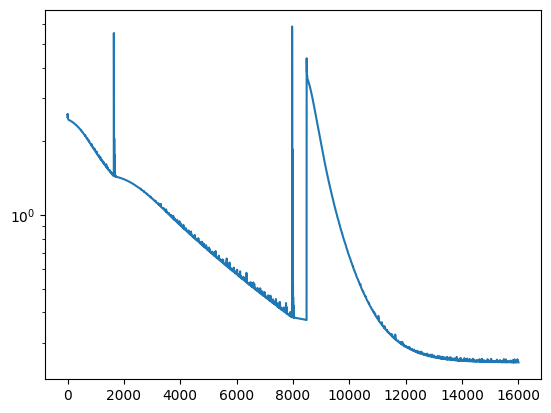

In [6]:
plt.plot(loss_bsplines_s)
plt.yscale('log')

In [8]:
epochs = 30000
learning_rate=1e-3

###########Changes#################
optimizer = torch.optim.Adam([model.coeffs_trainable, model.raw_c], lr=learning_rate)
###########Changes#################

loss_vec = []
for epoch in range(epochs):

    optimizer.zero_grad()

    u = model.forward(X)
    grads = torch.autograd.grad(u, X, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = grads[:, 0]
    u_t = grads[:, 1]
    u_xx = torch.autograd.grad(u_x, X, torch.ones_like(u_x), create_graph=True)[0][:, 0]
    u_tt = torch.autograd.grad(u_t, X, torch.ones_like(u_x), create_graph=True)[0][:, 1]

    c = model.c()

    # Residual loss
    res = u_tt -c**2*u_xx
    
    loss_pde = torch.mean(res**2)
    loss_data = torch.mean((u - u_exact)**2) 
    loss = loss_pde + loss_data

    loss.backward()
    optimizer.step()
    
    loss_vec.append(loss.item())
    # Print loss and parameters every 100 iterations
    if (epoch + 1) % 5 == 0:
        c_est = c.item()
        print(f"Epoch {epoch:5d} | Loss: {loss.item():.4e} | D: {c_est:.5f}")

Epoch     4 | Loss: 3.1304e+04 | D: 0.74230
Epoch     9 | Loss: 3.0062e+04 | D: 0.73969
Epoch    14 | Loss: 2.8864e+04 | D: 0.73711
Epoch    19 | Loss: 2.7713e+04 | D: 0.73455
Epoch    24 | Loss: 2.6609e+04 | D: 0.73203
Epoch    29 | Loss: 2.5552e+04 | D: 0.72954
Epoch    34 | Loss: 2.4542e+04 | D: 0.72710
Epoch    39 | Loss: 2.3577e+04 | D: 0.72471
Epoch    44 | Loss: 2.2657e+04 | D: 0.72236
Epoch    49 | Loss: 2.1779e+04 | D: 0.72005
Epoch    54 | Loss: 2.0942e+04 | D: 0.71779
Epoch    59 | Loss: 2.0144e+04 | D: 0.71558
Epoch    64 | Loss: 1.9384e+04 | D: 0.71341
Epoch    69 | Loss: 1.8658e+04 | D: 0.71129
Epoch    74 | Loss: 1.7967e+04 | D: 0.70921
Epoch    79 | Loss: 1.7307e+04 | D: 0.70717
Epoch    84 | Loss: 1.6678e+04 | D: 0.70517
Epoch    89 | Loss: 1.6078e+04 | D: 0.70321
Epoch    94 | Loss: 1.5504e+04 | D: 0.70128
Epoch    99 | Loss: 1.4957e+04 | D: 0.69940
Epoch   104 | Loss: 1.4434e+04 | D: 0.69755
Epoch   109 | Loss: 1.3933e+04 | D: 0.69574
Epoch   114 | Loss: 1.3455e+04 |

In [6]:
print(model.D().item())

0.7443966865539551


In [21]:
# Load model trainable parameters
model_s = bsplines2D(20,3,device)
loaded_params = torch.load('./results/wave_inverse/model_bsplines_noise.pth')
model_s.coeffs_trainable = loaded_params['coeffs_trainable']
model_s.raw_c = loaded_params['D_trainable']

C:\Users\Polydoras\AppData\Local\Temp\ipykernel_34652\322735783.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  loaded_params = torch.load('./results/wave_inverse/model_

In [17]:
# Load loss
loss_bsplines_s = np.load('./results/wave_inverse/bsplines_loss_noise.npy')

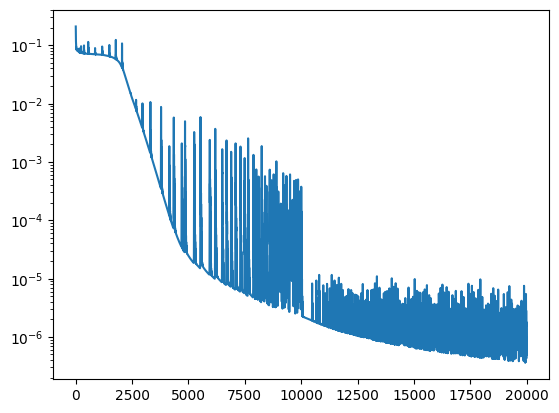

In [15]:
plt.plot(loss_pinn)
plt.yscale('log')

In [19]:
# 🔍 Evaluate on a grid
x = y = np.linspace(0, 1, 100)
Xg, Tg = np.meshgrid(x, y)
XY = np.vstack([Xg.ravel(), Tg.ravel()]).T
XY_torch = torch.tensor(XY, dtype=torch.float32)

# Prediction
with torch.no_grad():
    u_pred = model.forward(XY_torch).numpy().reshape(Xg.shape)

# ✅ Exact solution
u_exact = np.sin(2*np.pi * Xg) * np.exp(-np.pi**2 *0.03* Tg*4)


fig, axs = plt.subplots(1, 3, figsize=(15, 4))
# PINN solution
im0 = axs[0].imshow(u_pred, extent=[0,1,0,1], origin='lower', cmap='viridis')
axs[0].set_title("Physics_Informed_bsplines Solution")
fig.colorbar(im0, ax=axs[0])

# Exact solution
im1 = axs[1].imshow(u_exact, extent=[0,1,0,1], origin='lower', cmap='viridis')
axs[1].set_title("Exact Solution")
fig.colorbar(im1, ax=axs[1])

# Absolute error
error = np.abs(u_pred - u_exact)
im2 = axs[2].imshow(error, extent=[0,1,0,1], origin='lower', cmap='hot')
axs[2].set_title("Absolute Error")
fig.colorbar(im2, ax=axs[2])

for ax in axs:
    ax.set_xlabel("x")
    ax.set_ylabel("y")

plt.tight_layout()
plt.show()

TypeError: forward() missing 1 required positional argument: 'device'

PINN solution

In [1]:
import torch
import torch.nn as nn
from torch.optim.lr_scheduler import ReduceLROnPlateau
import numpy as np
import matplotlib.pyplot as plt

In [2]:

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Neural network model
class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 96), nn.Tanh(),
            nn.Linear(96, 96), nn.Tanh(),
            nn.Linear(96, 96), nn.Tanh(),
            nn.Linear(96, 1)
        )
        self.raw_D = nn.Parameter(torch.tensor([0.1], dtype=torch.float32))  # initial guess
        self.softplus = nn.Softplus()

    def forward(self, x, t):
        return self.net(torch.cat([x, t], dim=1))

    def D(self):
        return self.softplus(self.raw_D)  # ensures positivity

In [3]:
# Initialize mod
model = PINN().to(device)


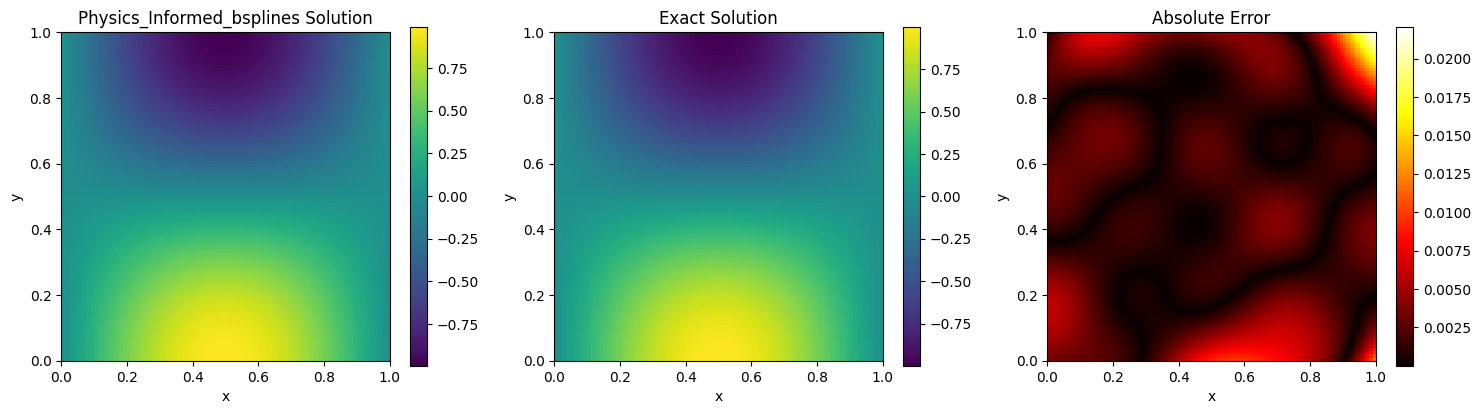

In [37]:
# 🔍 Evaluate on a test grid
x = y = np.linspace(0, 1, 100)
Xg, Tg = np.meshgrid(x, y)
XY = np.vstack([Xg.ravel(), Tg.ravel()]).T
XY_torch = torch.tensor(XY, dtype=torch.float32)
model_ps.cpu()
# Prediction
with torch.no_grad():
    u_pred = model_ps.forward(XY_torch[:,0].reshape(XY_torch.shape[0],1), XY_torch[:,1].reshape(XY_torch.shape[0],1)).numpy().reshape(Xg.shape)

# ✅ Exact solution
u_exact = np.sin(np.pi * Xg) * np.cos(np.pi*Tg)



fig, axs = plt.subplots(1, 3, figsize=(15, 4))
# PINN solution
im0 = axs[0].imshow(u_pred, extent=[0,1,0,1], origin='lower', cmap='viridis')
axs[0].set_title("Physics_Informed_bsplines Solution")
fig.colorbar(im0, ax=axs[0])

# Exact solution
im1 = axs[1].imshow(u_exact, extent=[0,1,0,1], origin='lower', cmap='viridis')
axs[1].set_title("Exact Solution")
fig.colorbar(im1, ax=axs[1])

# Absolute error
error = np.abs(u_pred - u_exact)
im2 = axs[2].imshow(error, extent=[0,1,0,1], origin='lower', cmap='hot')
axs[2].set_title("Absolute Error")
fig.colorbar(im2, ax=axs[2])

for ax in axs:
    ax.set_xlabel("x")
    ax.set_ylabel("y")

plt.tight_layout()
plt.show()

In [4]:
def pde_residual(model, x, t):
    
    x.requires_grad_(True)
    t.requires_grad_(True)
    u = model(x, t)
    c = model.D()

    u_t = torch.autograd.grad(u, t, torch.ones_like(u), retain_graph=True, create_graph=True)[0]
    u_tt = torch.autograd.grad(u_t, t, torch.ones_like(u), retain_graph=True, create_graph=True)[0]
    u_x = torch.autograd.grad(u, x, torch.ones_like(u), retain_graph=True, create_graph=True)[0]
    u_xx = torch.autograd.grad(u_x, x, torch.ones_like(u), create_graph=True)[0]

    return u_tt -u_xx*c 

In [5]:
def analytical_solution(x, t, c_true):
    return torch.sin(torch.pi * x) * torch.cos(torch.pi*t)

D_true=1
N_colloc = 5000
x_colloc = torch.rand(N_colloc, 1, device=device)
t_colloc = torch.rand(N_colloc, 1, device=device)
# x_data = torch.rand(N_data, 1, device=device)
# t_data = torch.rand(N_data, 1, device=device)
u_data = analytical_solution(x_colloc, t_colloc, D_true)

# Add noise
noise = torch.normal(mean=0.0, std=0.05, size=u_data.shape, device=device)
u_noisy = u_data + noise

In [7]:
u_data.shape

torch.Size([5000, 1])

In [7]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
# scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=1000, min_lr=1e-5, verbose=True)
model.to(device)
loss_history = []
for epoch in range(1000):
    optimizer.zero_grad()
    
    ##### Changes ####### 
    u_pred = model(x_colloc, t_colloc)
    ##### Changes ####### 

    loss_data = torch.mean((u_pred - u_data)**2)
    
    f = pde_residual(model, x_colloc, t_colloc)
    loss_pde = torch.mean(f**2)
    
    loss = loss_data + loss_pde
    loss.backward()
    optimizer.step()
    # scheduler.step(loss)
    loss_history.append(loss.item())
    if epoch % 500 == 0:
        D_est = model.D().item()
        print(f"Epoch {epoch:5d} | Loss: {loss.item():.4e} | D: {D_est:.5f}")
        

# Final estimated D
print(f"\nEstimated D: {model.D().item():.5f} (True D: {D_true})")

c:\Users\Polydoras\Documents\Sisc\PhD\PI_bsplines\.venv\lib\site-packages\torch\autograd\graph.py:769: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\cuda\CublasHandlePool.cpp:135.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Epoch     0 | Loss: 2.7664e-01 | D: 0.74492
Epoch   500 | Loss: 1.3385e-03 | D: 0.71550

Estimated D: 0.72925 (True D: 1)


In [9]:
# Load loss
loss_history = np.load('./results/wave_inverse/pinn_loss_noise.npy')

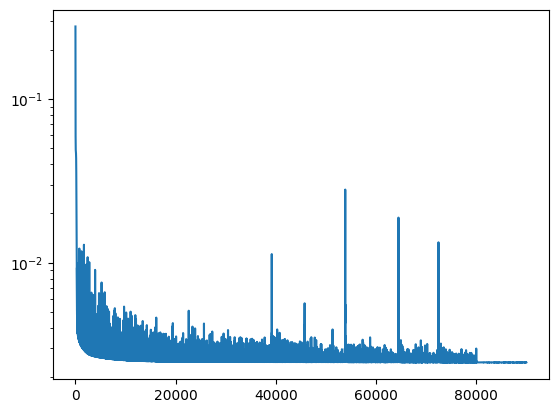

In [10]:
plt.plot(loss_history)
plt.yscale('log')

In [40]:
#Save loss
loss_vec_npy = np.array(loss_history)
np.save('./results/wave_inverse/pinn_loss_noise.npy', loss_vec_npy )

#Save model trainable parameters
torch.save(model.state_dict(), './results/wave_inverse/model_pinn_noise.pth')

In [36]:
#Load noisy model
model_ps = PINN()
model_ps.load_state_dict(torch.load('./results/wave_inverse/model_pinn_noise.pth'))


C:\Users\Polydoras\AppData\Local\Temp\ipykernel_43128\4210566090.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_ps.load_state_dict(torch.load('./results/wave_inve

<All keys matched successfully>

Table 7 and 8 for PINNs. first run the test grif and plot above to get the u_pred and u_exact

In [34]:
print(model_ps.D().item())

1.0163168907165527


In [38]:
re=np.sqrt((model_ps.D().item() - 1)**2)/np.sqrt(1**2)
re

0.016316890716552734

In [39]:
re = np.sqrt(np.sum((u_pred - u_exact)**2))/np.sqrt(np.sum(u_exact**2))
re.item()

0.006342319032320525

In [26]:
re.item()

0.0010129861381423595

In [40]:
(3.92-0.0634)/(3.92)

0.9838265306122449